# Do SAE Features Give More Faithful Explanations? Token Attribution and Feature Ablation for Few-Shot Sentiment in GPT-2 Small


## Research question
GPT-2 small classifies SST-2 movie-review sentiment from a 4-shot prompt. **Does a sparse autoencoder (SAE) give a more faithful explanation of which input tokens drive this decision than attention weights or gradient-based attributions? And do the SAE features it highlights causally matter?**

## Approach
1. **Token attribution.** Score each sentence token with six methods: attention, attention × gradient, **SAE gradient × activation**, raw-residual gradient × activation, a positional baseline (`last_k`) and random.
2. **Faithfulness.** Evaluate each ranking with ERASER-style *comprehensiveness* (remove the top-k tokens; the gold-label margin should drop) and *sufficiency* (keep only the top-k tokens; the margin should stay), with bootstrap CIs and paired tests (Bonferroni corrected).
3. **Feature-level causal test.** Rank SAE features on a **DEV half**, ablate the top-K on a **held-out TEST half**, and compare against *activation-matched random features* and a **non-SAE baseline** (difference-in-means sentiment direction vs. label-shuffled null directions).
4. **Validity checks.** Identity check on the attribution code, patched-forward-pass = original, and SAE reconstruction fidelity.

## Headline results (N = 200 sentences, 100 per class)
- **Attention × gradient is the most faithful token ranking** (comprehensiveness at k=5: 0.234 vs. SAE 0.080, raw grad×act 0.107, random 0.039; sufficiency at k=5: −0.001 vs. SAE 0.087, random 0.187). In paired tests SAE attribution is significantly worse than attention × gradient on comprehensiveness at every k.
- **SAE token attribution shows no clear advantage** over attention or raw gradient × activation. Its mean sufficiency is lower (better) than random at every k, but its comprehensiveness advantage over random does not survive Bonferroni correction at k=5 (p = 0.37), and at k=1 it is significantly *worse* than random (−0.041, Bonferroni p = 0.004).
- **At the feature level the SAE does find causally relevant features:** on held-out sentences, ablating the top-50 DEV-ranked features lowers the gold-label margin by 0.048 (NEG) / 0.101 (POS), versus about −0.014 / −0.002 for activation-matched random features. Ranking by activation mass alone (no gradient) already gives 0.011 / 0.082, so for POS sentences much of the effect comes from high-activation features in general.
- **- **A single difference-in-means direction is a strong non-SAE baseline, but the comparison depends on how it is projected out.** Full projection: 0.123 (POS) / −0.017 (NEG). Mean-centred projection: 0.055 (POS) / 0.037 (NEG), which is less than the top-50 SAE features (0.101 / 0.048).
- **Caveats matter here:** margins are small (mean 0.245 logits), the few-shot prompt is biased towards "negative", the SAE is lossy at this layer, and the token-level comparison mixes attributions taken at different depths (see *Limitations* at the end).

## 1. Setup
Imports, global configuration and fixed seeds. `QUICK = False` is the real run. Results go to `results/` and figures to `figures/`. A checkpoint file allows the long main loop to resume after an interruption.

In [1]:
import os, random, pickle, json, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy import stats
from datasets import load_dataset
from transformer_lens import HookedTransformer
from sae_lens import SAE
%matplotlib inline

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

In [2]:
QUICK = False           # False = real run (results go to results/ and figures/)
RESUME = True           # resume the main loop from a checkpoint if one exists

SEED = 0
N_PER_CLASS = 20 if QUICK else 100       # CPU-friendly
KS = [1, 2, 3, 5, 8]                     # tokens removed / kept
R_RANDOM = 3             # random-ranking draws per example
KF = [1, 5, 10, 20, 50]                  # number of SAE features ablated (Section 7)
R_FEAT = 4 if QUICK else 5               # random feature sets per K
R_DIR = 8 if QUICK else 15               # null directions for the direction baseline
BATCH = 64                               # masked / ablated copies per forward pass
EPS_DENOM = 0.25                         # min (m_full - m_blank) for normalised metrics

# separate output folders so a QUICK run never overwrites real results
RES = "results/quick" if QUICK else "results"
FIG = "figures/quick" if QUICK else "figures"
for d in ["data", "writeup", RES, FIG]:
    os.makedirs(d, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| QUICK:", QUICK, "| results ->", RES)
if device.type == "cpu":
    print("CPU detected: this real run will take hours. Keep the laptop plugged in and awake.")

device: cpu | QUICK: False | results -> results
CPU detected: this real run will take hours. Keep the laptop plugged in and awake.


## 2. Model and SAE
Load GPT-2 small and the layer-8 residual-stream SAE released by Joseph Bloom (`gpt2-small-res-jb`). All model parameters are frozen; gradients are only taken with respect to activations.

In [3]:
LAYER = 8
SAE_RELEASE = "gpt2-small-res-jb"
HOOK_NAME = f"blocks.{LAYER}.hook_resid_pre"      # for this release the SAE id == hook name

model = HookedTransformer.from_pretrained("gpt2-small", device=str(device))
model.eval()
model.requires_grad_(False)          # we only need gradients w.r.t. activations
N_LAYERS = model.cfg.n_layers        # 12

out = SAE.from_pretrained(release=SAE_RELEASE, sae_id=HOOK_NAME, device=str(device))
sae = out[0] if isinstance(out, tuple) else out   # older SAELens returns (sae, cfg, sparsity)
sae.eval()
sae.requires_grad_(False)
D_SAE = sae.W_dec.shape[0]
print("SAE features:", D_SAE, "| d_model:", sae.W_dec.shape[1], "| n_layers:", N_LAYERS)

C:\Users\jenil\AppData\Local\Temp\ipykernel_13672\951569829.py:5: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2-small", device=str(device))


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded pretrained model gpt2-small into HookedTransformer
SAE features: 24576 | d_model: 768 | n_layers: 12


C:\Users\jenil\.conda\envs\PROJECT\Lib\site-packages\sae_lens\saes\sae.py:256: UserWarning: 
This SAE has non-empty model_from_pretrained_kwargs. 
For optimal performance, load the model like so:
model = HookedSAETransformer.from_pretrained_no_processing(..., **cfg.model_from_pretrained_kwargs)
  warnings.warn(


### SAE sanity checks
Before trusting any SAE-based number we check that (i) the decoder is linear (`decode(f) = f @ W_dec + b_dec`), which the ablation code relies on, (ii) reconstruction error is reasonable (we get **0.21** relative error on non-BOS tokens), and (iii) the number of active features per token is plausible (**~60 of 24,576**).

In [4]:
# ---- SAE sanity checks (do not skip) ----
x_ids = model.to_tokens("The movie was surprisingly good, and the ending was great.")
with torch.no_grad():
    _, cache = model.run_with_cache(x_ids, names_filter=HOOK_NAME)
resid = cache[HOOK_NAME]
f = sae.encode(resid)
recon = sae.decode(f)

linear_ok = torch.allclose(recon, f @ sae.W_dec + sae.b_dec, atol=1e-3)
print("linear decoder:", linear_ok)
rel_err = ((resid[:, 1:] - recon[:, 1:]).norm() / resid[:, 1:].norm()).item()   # skip BOS (huge norm)
print("relative reconstruction error (non-BOS):", round(rel_err, 3))
n_active = (f[:, 1:] > 0).float().sum(-1).mean().item()
print("avg #active features / token:", round(n_active, 1))

assert linear_ok, "decode(f) != f @ W_dec + b_dec : this SAE applies extra normalisation; Section 7 ablation must be rewritten"
assert rel_err < 0.5, "reconstruction error >= 0.5: wrong hook point / release?"
assert n_active < 1000, "thousands of active features/token: wrong hook point or release loaded"

linear decoder: True
relative reconstruction error (non-BOS): 0.211
avg #active features / token: 59.8


## 3. Task and prompt
A fixed 4-shot prompt (2 positive, 2 negative) followed by `Review: <sentence>\nSentiment:`. The prediction is the sign of
$$\text{logit}(\text{" positive"}) - \text{logit}(\text{" negative"})$$
at the last position. The **gold-label margin** = (sign of gold label) × (logit difference) is the quantity every method tries to explain; margin > 0 means the model is correct.

#### Few-shot prompt

In [5]:
FEWSHOT = [
    ("a gorgeous , witty and deeply moving film .", "positive"),
    ("a dull , lifeless mess with no redeeming qualities .", "negative"),
    ("the performances are wonderful and the story is engaging .", "positive"),
    ("it is boring , predictable and far too long .", "negative"),
]
PREFIX = "".join(f"Review: {t}\nSentiment: {l}\n\n" for t, l in FEWSHOT) + "Review:"
SUFFIX = "\nSentiment:"

#### Answer tokens and prompt token ids

In [6]:
POS = model.to_single_token(" positive")     # raises if not a single token
NEG = model.to_single_token(" negative")

PRE_IDS = model.to_tokens(PREFIX, prepend_bos=True)[0]
SUF_IDS = model.to_tokens(SUFFIX, prepend_bos=False)[0]

#### Helpers: `build_tokens` and `logit_diff`

In [7]:
def build_tokens(sentence):
    """Return (tokens [1, T], span). span = (start, end) of the sentence tokens inside the prompt."""
    sent = model.to_tokens(" " + sentence.strip(), prepend_bos=False)[0]
    toks = torch.cat([PRE_IDS, sent, SUF_IDS]).unsqueeze(0).to(device)
    return toks, (len(PRE_IDS), len(PRE_IDS) + len(sent))

@torch.no_grad()
def logit_diff(tokens):
    """logit(' positive') - logit(' negative') at the last position."""
    lg = model(tokens)[0, -1]
    return (lg[POS] - lg[NEG]).item()

#### Example: tokenised sentence inside the prompt

In [8]:
toks, span = build_tokens("a warm and funny film .")
print(model.to_str_tokens(toks[0, span[0]:span[1]]))
print("T =", toks.shape[1], "| prefix tokens:", len(PRE_IDS), "| suffix tokens:", len(SUF_IDS),
      "| logit diff:", round(logit_diff(toks), 3))

[' a', ' warm', ' and', ' funny', ' film', ' .']
T = 89 | prefix tokens: 79 | suffix tokens: 4 | logit diff: -0.31


### Baseline accuracy on SST-2 validation
Few-shot accuracy is **0.658**, which is modest for GPT-2 small. The model is biased towards "negative": it predicts positive on only 23% of sentences (true rate 51%), with accuracy 0.94 on negative and 0.39 on positive sentences. This affects how the evaluation set is built, and is discussed in the limitations.

In [9]:
# ---- baseline accuracy on SST-2 validation (872 sentences) ----
ds = load_dataset("nyu-mll/glue", "sst2", split="validation")
df = pd.DataFrame({"sentence": [s.strip() for s in ds["sentence"]], "label": ds["label"]})

ld, ntok = [], []
for s in tqdm(df.sentence):
    t, sp = build_tokens(s)
    ld.append(logit_diff(t)); ntok.append(sp[1] - sp[0])
df["ld"], df["n_tok"] = ld, ntok
df["sgn"] = np.where(df.label == 1, 1, -1)
df["margin"] = df.sgn * df.ld          # > 0  <=>  prediction correct
df["correct"] = df.margin > 0

ACC = float(df.correct.mean())
print("few-shot accuracy      :", round(ACC, 3))
print("predicted-positive rate:", round((df.ld > 0).mean(), 3), "| true-positive rate:", round(df.label.mean(), 3))
print(df.groupby("label").correct.mean().round(3))

  0%|          | 0/872 [00:00<?, ?it/s]

few-shot accuracy      : 0.658
predicted-positive rate: 0.232 | true-positive rate: 0.509
label
0    0.935
1    0.392
Name: correct, dtype: float64


### Evaluation set
Only sentences the model **classifies correctly** and that are 10–40 tokens long are kept (the whole prompt must fit in the 128-token context the SAE was trained on). We sample 100 per class. Restricting to correct predictions means the margin we explain is positive, but it also means the sample is not representative of all sentences.

In [10]:
MIN_TOK = 10
MAX_TOK = min(40, 128 - len(PRE_IDS) - len(SUF_IDS))   # whole prompt <= 128 tokens (SAE training context)
assert MIN_TOK > max(KS), "MIN_TOK must exceed max(KS) so every k is valid"
assert len(PRE_IDS) + len(SUF_IDS) + MAX_TOK <= 128
print("sentence length window:", MIN_TOK, "-", MAX_TOK, "tokens")

cand = df[df.correct & df.n_tok.between(MIN_TOK, MAX_TOK)]
print("candidates per class (correct + length filter):", cand.label.value_counts().to_dict())

parts = [cand[cand.label == c].sample(min(N_PER_CLASS, int((cand.label == c).sum())), random_state=SEED)
         for c in (0, 1)]
sel = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
sel.to_csv("data/selected_examples.csv" if not QUICK else f"{RES}/selected_examples.csv", index=False)

print(len(sel), "examples |", sel.label.value_counts().to_dict(), "| mean #tokens:", round(sel.n_tok.mean(), 1))
assert sel.label.nunique() == 2 and sel.label.value_counts().min() >= 5, "too few examples in a class: lower filters / fix prompt"

sentence length window: 10 - 40 tokens
candidates per class (correct + length filter): {0: 337, 1: 155}
200 examples | {0: 100, 1: 100} | mean #tokens: 24.4


## 4. Attribution methods
All methods produce one score per sentence token with respect to the gold-label margin.

| Method | Idea |
|---|---|
| `attention` | Attention from the last position to each sentence token, averaged over heads and layers |
| `attn_x_grad` | Attention × ∂margin/∂attention, summed over heads and layers |
| `sae` | Gradient × activation w.r.t. SAE feature activations at layer 8, with the SAE reconstruction-error term held fixed |
| `raw_gradxact` | Gradient × activation on the raw residual stream at the same hook point (control without SAE) |
| `last_k` | Positional baseline: later tokens score higher |
| `random` | Random ranking, 3 draws per sentence |

#### `attention`: attention paid by the last position

In [11]:
@torch.no_grad()
def attention_scores(tokens, span, layers=None):
    """Attention paid by the LAST position to each sentence token, averaged over heads and layers."""
    layers = list(range(N_LAYERS)) if layers is None else list(layers)
    _, cache = model.run_with_cache(tokens, names_filter=lambda n: n.endswith("attn.hook_pattern"))
    last = torch.stack([cache[f"blocks.{l}.attn.hook_pattern"][0, :, -1, :] for l in layers])   # [L, H, K]
    return last.mean(dim=(0, 1))[span[0]:span[1]]

#### `attn_x_grad`: attention × gradient

In [12]:
def attn_x_grad_scores(tokens, sign, span):
    """attention x d(margin)/d(attention) for the last-position row, summed over heads and layers."""
    store = {}
    def embed_hook(emb, hook):
        return emb.detach().clone().requires_grad_(True)       # makes the whole graph differentiable
    def make_save(l):
        def save(pat, hook):
            pat.retain_grad()
            store[l] = pat
            return pat
        return save
    hooks = [("hook_embed", embed_hook)] + [(f"blocks.{l}.attn.hook_pattern", make_save(l)) for l in range(N_LAYERS)]
    lg = model.run_with_hooks(tokens, fwd_hooks=hooks)[0, -1]
    (sign * (lg[POS] - lg[NEG])).backward()
    tot = 0
    for l in range(N_LAYERS):
        p = store[l]
        tot = tot + (p * p.grad)[0, :, -1, :].sum(0)             # [K], summed over heads
    return tot.detach()[span[0]:span[1]]

#### `sae`: gradient × activation on SAE features

In [13]:
def sae_attribution(tokens, sign, span):
    """Gradient x activation w.r.t. SAE feature activations. The SAE error term is held constant,
    so the patched forward pass equals the original one.
    Returns: token scores [n], per-feature contributions [n, d_sae], feature acts [n, d_sae],
             patched margin (float), residual stream over the span [n, d_model]."""
    with torch.no_grad():
        _, cache = model.run_with_cache(tokens, names_filter=HOOK_NAME)
        resid = cache[HOOK_NAME]
        f0 = sae.encode(resid)                       # [1, T, d_sae]
        err = resid - sae.decode(f0)                 # what the SAE fails to reconstruct
    f = f0.clone().requires_grad_(True)
    def patch(act, hook):
        return sae.decode(f) + err
    lg = model.run_with_hooks(tokens, fwd_hooks=[(HOOK_NAME, patch)])[0, -1]
    m = sign * (lg[POS] - lg[NEG])
    m.backward()
    contrib = (f * f.grad)[0].detach()               # [T, d_sae]
    s0, s1 = span
    return contrib[s0:s1].sum(-1), contrib[s0:s1], f0[0, s0:s1], m.item(), resid[0, s0:s1]

#### `raw_gradxact`: gradient × activation without the SAE (control)

In [14]:
def raw_attribution(tokens, sign, span):
    """Control: gradient x activation on the raw residual stream (no SAE) at the same hook point."""
    with torch.no_grad():
        _, cache = model.run_with_cache(tokens, names_filter=HOOK_NAME)
    x = cache[HOOK_NAME].clone().requires_grad_(True)
    lg = model.run_with_hooks(tokens, fwd_hooks=[(HOOK_NAME, lambda act, hook: x)])[0, -1]
    (sign * (lg[POS] - lg[NEG])).backward()
    return (x * x.grad)[0].sum(-1)[span[0]:span[1]].detach()

#### `last_k`: positional baseline

In [15]:
def last_k_scores(n):
    """Positional baseline: later tokens score higher."""
    return torch.arange(n, dtype=torch.float32)

### Correctness checks for the attribution code
Because the SAE error term is held constant, the patched forward pass must reproduce the original margin exactly, and the SAE token score must equal $(\hat{x} - b_{dec}) \cdot g$, where $g = \partial\,\text{margin} / \partial x$ is the gradient w.r.t. the residual stream. Both checks pass (max abs difference 0.0).

**Note:** this identity also shows that the *token-level* SAE score is the raw gradient × activation **minus** the bias and reconstruction-error terms, i.e. `raw = sae_score + (b_dec + error) · g`. The two rankings are therefore not the same: their mean Spearman correlation is −0.155 and their top-1 token agrees in only 9.5% of sentences (Section 6). The SAE's added value is the per-feature decomposition used in Section 7, not the token ranking itself.

#### Identity check function

In [16]:
def identity_check(tokens, sign, span):
    """SAE token score must equal (x_hat - b_dec) . g where g = d margin / d residual."""
    with torch.no_grad():
        _, cache = model.run_with_cache(tokens, names_filter=HOOK_NAME)
        x = cache[HOOK_NAME]
        x_hat = sae.decode(sae.encode(x))
    xg = x.clone().requires_grad_(True)
    lg = model.run_with_hooks(tokens, fwd_hooks=[(HOOK_NAME, lambda act, hook: xg)])[0, -1]
    (sign * (lg[POS] - lg[NEG])).backward()
    g = xg.grad[0]
    lhs = ((x_hat[0] - sae.b_dec) * g).sum(-1)[span[0]:span[1]]
    rhs, _, _, m_patched, _ = sae_attribution(tokens, sign, span)
    ok = torch.allclose(lhs, rhs, atol=1e-3, rtol=1e-2)
    return ok, (lhs - rhs).abs().max().item(), m_patched

#### Run the identity check on three sentences

In [17]:
for i in range(min(3, len(sel))):
    r = sel.iloc[i]
    t, sp = build_tokens(r["sentence"])
    ok, err_, m_patched = identity_check(t, int(r["sgn"]), sp)
    print("identity holds:", ok, "| max abs diff:", round(err_, 6),
          "| patched margin", round(m_patched, 4), "vs original", round(float(r["margin"]), 4))
    assert ok, "identity check failed: hook / error term / gradient plumbing is wrong"
    assert abs(m_patched - float(r["margin"])) < 1e-2, "patched forward pass != original forward pass"

identity holds: True | max abs diff: 0.0 | patched margin 0.5832 vs original 0.5832
identity holds: True | max abs diff: 0.0 | patched margin 0.0775 vs original 0.0775
identity holds: True | max abs diff: 0.0 | patched margin 0.0694 vs original 0.0694


In [18]:
# ---- sanity of the other scorers ----
r = sel.iloc[0]
t, sp = build_tokens(r["sentence"]); sg = int(r["sgn"]); n_ = sp[1] - sp[0]
for name, sc_ in {"attention": attention_scores(t, sp),
                  "attn_x_grad": attn_x_grad_scores(t, sg, sp),
                  "sae": sae_attribution(t, sg, sp)[0],
                  "raw_gradxact": raw_attribution(t, sg, sp)}.items():
    assert sc_.shape == (n_,) and torch.isfinite(sc_).all(), f"{name}: bad shape or non-finite scores"
    print(f"{name:13s} OK  shape={tuple(sc_.shape)}  top token = {model.to_str_tokens(t[0, sp[0]:sp[1]])[int(sc_.argmax())]!r}")

attention     OK  shape=(10,)  top token = ' .'
attn_x_grad   OK  shape=(10,)  top token = ' headache'
sae           OK  shape=(10,)  top token = ' headache'
raw_gradxact  OK  shape=(10,)  top token = ' a'


## 5. Faithfulness evaluation by masking
To remove a token we replace its **embedding with the mean token embedding** (a "blank" token); the positional embedding is kept.

- **Comprehensiveness(k)** = margin(full) − margin(top-k removed). Higher is more faithful.
- **Sufficiency(k)** = margin(full) − margin(only top-k kept). Lower is more faithful.
- k ∈ {1, 2, 3, 5, 8}. A random-ranking baseline (3 draws) is included. Normalised versions divide by (margin(full) − margin(all blanked)) and are only computed when that denominator exceeds 0.25.

A gate cell first checks that batched masking with no mask reproduces the original margin.

#### Blank token and batched masking

In [19]:
BLANK = model.W_E.detach().mean(0)          # "blank" token = mean embedding vector

@torch.no_grad()
def masked_margins(tokens, sign, pos_lists, bs=BATCH):
    """Gold-label margin after blanking the token embeddings at each list of positions.
    One forward pass handles up to `bs` masked copies of the same prompt."""
    out = []
    T = tokens.shape[1]
    for s in range(0, len(pos_lists), bs):
        chunk = pos_lists[s:s + bs]
        B = len(chunk)
        mask = torch.zeros(B, T, dtype=torch.bool, device=device)
        for b, p in enumerate(chunk):
            if len(p):
                mask[b, p] = True
        def hook(emb, hook, mask=mask):
            emb = emb.clone()
            emb[mask] = BLANK
            return emb
        lg = model.run_with_hooks(tokens.expand(B, -1), fwd_hooks=[("hook_embed", hook)])[:, -1]
        out.append((sign * (lg[:, POS] - lg[:, NEG])).float().cpu().numpy())
    return np.concatenate(out)

#### Faithfulness metrics for one sentence

In [20]:
def eval_example(tokens, sign, span, scores, m_full, gen):
    """All faithfulness numbers for one sentence. `scores` = {method: score tensor [n]}.
    Ties are broken by position (stable sort)."""
    n = span[1] - span[0]; b0 = span[0]
    lists, keys = [], []
    def add(name, order, r=0):
        for k in KS:
            lists.append([b0 + j for j in order[:k]]); keys.append((name, k, "top", r))
            lists.append([b0 + j for j in order[k:]]); keys.append((name, k, "rest", r))
    for name, sc in scores.items():
        add(name, torch.argsort(sc.detach().float().cpu(), descending=True, stable=True).tolist())
    for r in range(R_RANDOM):
        add("random", torch.randperm(n, generator=gen).tolist(), r)
    lists.append(list(range(b0, b0 + n))); keys.append(("blank", 0, "all", 0))
    marg = dict(zip(keys, masked_margins(tokens, sign, lists)))
    m_blank = float(marg[("blank", 0, "all", 0)])
    recs = []
    for name in list(scores) + ["random"]:
        for k in KS:
            rs = range(R_RANDOM) if name == "random" else [0]
            comp = float(np.mean([m_full - marg[(name, k, "top", r)] for r in rs]))
            suff = float(np.mean([m_full - marg[(name, k, "rest", r)] for r in rs]))
            recs.append(dict(method=name, k=k, comp=comp, suff=suff))
    return recs, m_blank

#### Gate check: masking nothing must reproduce the original margin

In [21]:
# ---- GATE cell for masking ----
t, sp = build_tokens(sel.loc[0, "sentence"]); sg = int(sel.loc[0, "sgn"])
chk = masked_margins(t, sg, [[], list(range(sp[0], sp[1]))])
print("no-mask margin:", round(float(chk[0]), 4), "| original:", round(sg * logit_diff(t), 4),
      "| all-sentence-masked margin:", round(float(chk[1]), 4))
assert abs(chk[0] - sg * logit_diff(t)) < 1e-2, "batched masking with no mask != original margin"

no-mask margin: 0.5832 | original: 0.5832 | all-sentence-masked margin: 0.0803


## 6. Main loop
For each of the 200 sentences: compute all six attributions, run the masking evaluation, and accumulate SAE feature statistics. **Even-indexed sentences form the DEV half** (used to rank SAE features); **odd-indexed sentences are held out as TEST** and are never used to choose features. Progress is checkpointed every 25 sentences.

#### Checkpoint state and resume

In [22]:
CKPT = f"{RES}/_ckpt.pkl"
CKPT_EVERY = 25

def new_state():
    return dict(next=0, records=[], agree=[], dev_vecs=[],
                feat_sum=torch.zeros(2, D_SAE), feat_ex=torch.zeros(2, D_SAE), feat_asum=torch.zeros(2, D_SAE),
                feat_n=[0, 0], feat_sub=torch.zeros(2, 2, D_SAE), feat_nsub=[[0, 0], [0, 0]])

state = new_state()
if RESUME and os.path.exists(CKPT):
    with open(CKPT, "rb") as fh:
        ck = pickle.load(fh)
    if ck.get("n") == len(sel):
        state = ck
        print("resuming from example", state["next"], "of", len(sel))
    else:
        print("checkpoint is for a different selection; starting fresh")

records, agree, dev_vecs = state["records"], state["agree"], state["dev_vecs"]
feat_sum, feat_ex, feat_asum = (state[k].to(device) for k in ("feat_sum", "feat_ex", "feat_asum"))
feat_sub = state["feat_sub"].to(device)
feat_n, feat_nsub = state["feat_n"], state["feat_nsub"]

resuming from example 200 of 200


#### Helpers and method list

In [23]:
def save_ckpt(i_next):
    with open(CKPT, "wb") as fh:
        pickle.dump(dict(n=len(sel), next=i_next, records=records, agree=agree, dev_vecs=dev_vecs,
                         feat_sum=feat_sum.cpu(), feat_ex=feat_ex.cpu(), feat_asum=feat_asum.cpu(),
                         feat_n=feat_n, feat_sub=feat_sub.cpu(), feat_nsub=feat_nsub), fh)

def safe_spearman(a, b):
    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return stats.spearmanr(a, b)[0]

METHODS = ["attention", "attn_x_grad", "sae", "raw_gradxact", "last_k"]
METHODS_ALL = METHODS + ["random"]

#### Run all 200 sentences

In [24]:
for i in tqdm(range(state["next"], len(sel))):
    row = sel.iloc[i]
    toks, span = build_tokens(row["sentence"])
    sign, lab = int(row["sgn"]), int(row["label"])
    n = span[1] - span[0]
    m_full = sign * logit_diff(toks)

    sc = {"attention": attention_scores(toks, span),
          "attn_x_grad": attn_x_grad_scores(toks, sign, span)}
    sc["sae"], contrib, f_span, m_patched, resid_span = sae_attribution(toks, sign, span)
    sc["raw_gradxact"] = raw_attribution(toks, sign, span)
    sc["last_k"] = last_k_scores(n)
    assert abs(m_patched - m_full) < 1e-2, "patched forward pass != original forward pass"

    # DEV half (even rows) -> feature statistics for Section 7; odd rows are held out (TEST)
    if i % 2 == 0:
        feat_sum[lab] += contrib.sum(0)
        feat_ex[lab] += (f_span > 0).any(0).float()
        feat_asum[lab] += f_span.sum(0)
        feat_n[lab] += 1
        sub = (i // 2) % 2
        feat_sub[sub, lab] += contrib.sum(0)
        feat_nsub[sub][lab] += 1
        dev_vecs.append((lab, resid_span.mean(0).detach().cpu()))

    a, g_, s_, r_ = (sc[k].detach().cpu().numpy() for k in ("attention", "attn_x_grad", "sae", "raw_gradxact"))
    agree.append(dict(id=i,
                      rho_attn_sae=safe_spearman(a, s_), rho_attngrad_sae=safe_spearman(g_, s_),
                      rho_sae_raw=safe_spearman(s_, r_),
                      resid_ratio=float(np.abs(r_ - s_).mean() / (np.abs(r_).mean() + 1e-9)),
                      top1_attn_sae=int(a.argmax() == s_.argmax()), top1_sae_raw=int(s_.argmax() == r_.argmax())))

    gen = torch.Generator().manual_seed(SEED * 100003 + i)       # per-example seed -> resumable
    recs, m_blank = eval_example(toks, sign, span, sc, m_full, gen)
    for rc in recs:
        rc.update(id=i, label=lab, m_full=m_full, m_blank=m_blank, denom=m_full - m_blank)
    records.extend(recs)

    if (i + 1) % CKPT_EVERY == 0:
        save_ckpt(i + 1)

0it [00:00, ?it/s]

#### Save results

In [25]:
save_ckpt(len(sel))

res = pd.DataFrame(records)
res.to_csv(f"{RES}/per_example.csv", index=False)
pd.DataFrame(agree).to_csv(f"{RES}/rank_agreement.csv", index=False)
torch.save({"feat_sum": feat_sum.cpu(), "feat_ex": feat_ex.cpu(), "feat_asum": feat_asum.cpu(), "feat_n": feat_n},
           f"{RES}/feature_stats.pt")
print(res.groupby("method").size())

method
attention       1000
attn_x_grad     1000
last_k          1000
random          1000
raw_gradxact    1000
sae             1000
dtype: int64


### Token-level results
Means with 95% bootstrap CIs per method and k, an AOPC-style average over k, and rank agreement between explanations. Note that only 97 of 200 sentences have a margin gap above 0.25, so the normalised metrics use about half the data.

#### Normalised metrics

In [26]:
res["comp_n"] = np.where(res.denom > EPS_DENOM, res.comp / res.denom, np.nan)
res["suff_n"] = np.where(res.denom > EPS_DENOM, res.suff / res.denom, np.nan)
u = res.drop_duplicates("id")
print(f"examples with m_full - m_blank > {EPS_DENOM}: {(u.denom > EPS_DENOM).sum()} / {len(u)} (used for normalised metrics)")
print("mean m_full:", round(u.m_full.mean(), 3), "| mean m_blank:", round(u.m_blank.mean(), 3))
res.to_csv(f"{RES}/per_example.csv", index=False)

examples with m_full - m_blank > 0.25: 97 / 200 (used for normalised metrics)
mean m_full: 0.245 | mean m_blank: -0.005


#### Bootstrap confidence intervals

In [27]:
def boot_ci(x, n_boot=2000, seed=SEED):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if len(x) == 0:
        return (np.nan, np.nan)
    rng_ = np.random.default_rng(seed)
    means = x[rng_.integers(0, len(x), (n_boot, len(x)))].mean(1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return lo, hi

METRICS = ["comp", "suff", "comp_n", "suff_n"]
rows = []
for (method, k), g in res.groupby(["method", "k"]):
    for m in METRICS:
        x = g[m].dropna().values
        lo, hi = boot_ci(x)
        rows.append(dict(method=method, k=k, metric=m, n=len(x),
                         mean=float(x.mean()) if len(x) else np.nan, lo=lo, hi=hi))
summ = pd.DataFrame(rows)
summ.to_csv(f"{RES}/faithfulness_summary.csv", index=False)

#### Mean comprehensiveness and sufficiency per method and k

In [28]:
order_cols = [c for c in METHODS_ALL if c in set(summ.method)]
print("Comprehensiveness (higher = more faithful)")
print(summ[summ.metric == "comp"].pivot(index="k", columns="method", values="mean")[order_cols].round(3))
print("\nSufficiency (lower = more faithful)")
print(summ[summ.metric == "suff"].pivot(index="k", columns="method", values="mean")[order_cols].round(3))

Comprehensiveness (higher = more faithful)
method  attention  attn_x_grad    sae  raw_gradxact  last_k  random
k                                                                  
1           0.028        0.087 -0.038         0.028   0.032   0.003
2           0.035        0.153  0.006         0.046   0.029   0.007
3           0.053        0.194  0.039         0.073   0.040   0.010
5           0.095        0.234  0.080         0.107   0.073   0.039
8           0.148        0.297  0.133         0.165   0.112   0.096

Sufficiency (lower = more faithful)
method  attention  attn_x_grad    sae  raw_gradxact  last_k  random
k                                                                  
1           0.230        0.170  0.204         0.183   0.229   0.239
2           0.204        0.117  0.174         0.144   0.200   0.230
3           0.182        0.075  0.142         0.122   0.186   0.220
5           0.145       -0.001  0.087         0.078   0.149   0.187
8           0.064       -0.083  0.05

#### AOPC-style average over k

In [29]:
aopc = res.groupby(["method", "id"])[["comp", "suff", "comp_n", "suff_n"]].mean().groupby("method").agg(["mean", "std"]).round(3)
print("\nAOPC-style average over k (per method):")
print(aopc)
aopc.to_csv(f"{RES}/aopc_summary.csv")


AOPC-style average over k (per method):
               comp          suff        comp_n        suff_n       
               mean    std   mean    std   mean    std   mean    std
method                                                              
attention     0.072  0.213  0.165  0.176  0.371  0.623  0.576  0.436
attn_x_grad   0.193  0.242  0.056  0.178  0.702  0.671  0.313  0.450
last_k        0.057  0.098  0.170  0.226  0.213  0.249  0.693  0.524
random        0.031  0.168  0.201  0.178  0.185  0.497  0.775  0.387
raw_gradxact  0.084  0.204  0.110  0.223  0.332  0.528  0.556  0.553
sae           0.044  0.206  0.132  0.175  0.262  0.580  0.529  0.430


#### Rank agreement between explanations

In [30]:
agree_df = pd.DataFrame(agree)
print("\nRank agreement between explanations (mean over sentences; NaN rows skipped):")
print(agree_df.drop(columns="id").mean().round(3))


Rank agreement between explanations (mean over sentences; NaN rows skipped):
rho_attn_sae        0.095
rho_attngrad_sae    0.418
rho_sae_raw        -0.155
resid_ratio         5.574
top1_attn_sae       0.500
top1_sae_raw        0.095
dtype: float64


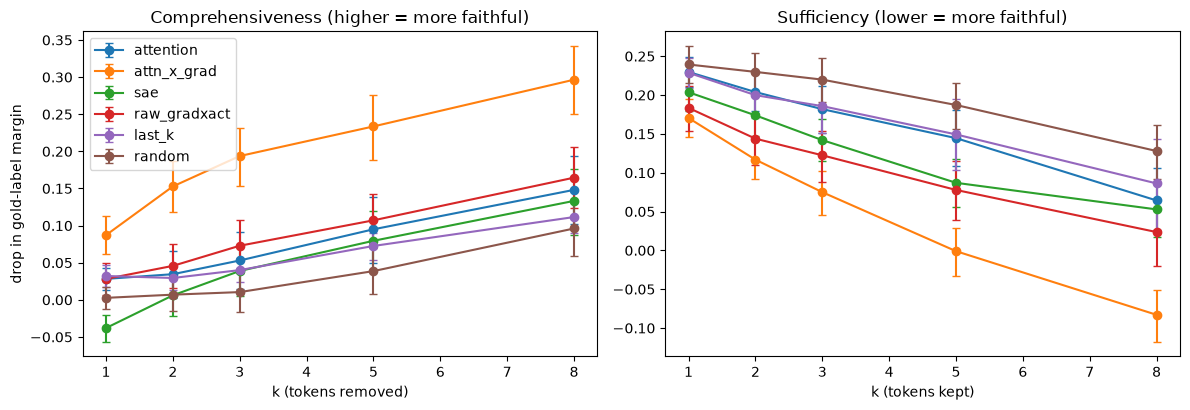

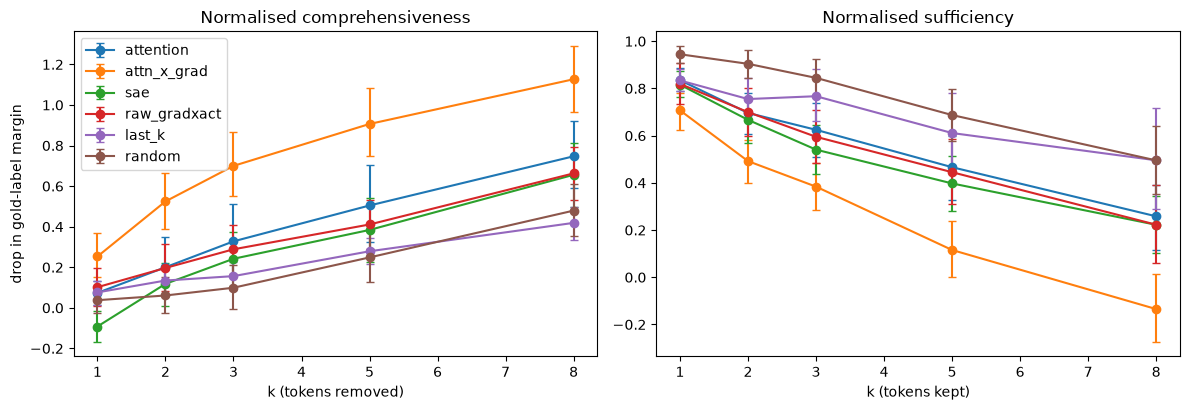

In [31]:
def plot_curves(mc, ms, title_c, title_s, fname):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for method in METHODS_ALL:
        for a_, m in zip(ax, (mc, ms)):
            g = summ[(summ.method == method) & (summ.metric == m)].sort_values("k")
            a_.errorbar(g.k, g["mean"], yerr=[g["mean"] - g.lo, g.hi - g["mean"]],
                        marker="o", capsize=3, label=method)
    ax[0].set(title=title_c, xlabel="k (tokens removed)", ylabel="drop in gold-label margin")
    ax[1].set(title=title_s, xlabel="k (tokens kept)")
    ax[0].legend()
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

plot_curves("comp", "suff", "Comprehensiveness (higher = more faithful)", "Sufficiency (lower = more faithful)",
            f"{FIG}/faithfulness_curves.png")
plot_curves("comp_n", "suff_n", "Normalised comprehensiveness", "Normalised sufficiency",
            f"{FIG}/faithfulness_curves_normalised.png")

### Paired significance tests
Paired t-tests and Wilcoxon tests between methods at each k (effect size dz = mean difference / SD of differences). Bonferroni correction is applied over all 140 tests, which is conservative because comprehensiveness and its normalised version are highly correlated. For `comp`, method A is more faithful if the mean difference is > 0; for `suff`, if it is < 0.

#### Paired test function

In [32]:
def paired_tests(res, metric, a, b, n_tests):
    out = []
    for k in KS:
        piv = res[res.k == k].pivot(index="id", columns="method", values=metric)
        d = (piv[a] - piv[b]).dropna().values
        if len(d) < 3:
            continue
        p_t = stats.ttest_1samp(d, 0.0).pvalue
        try:
            p_w = stats.wilcoxon(d).pvalue
        except ValueError:
            p_w = np.nan
        sd = d.std(ddof=1)
        out.append(dict(metric=metric, A=a, B=b, k=k, n=len(d), mean_diff=d.mean(),
                        dz=(d.mean() / sd) if sd > 0 else np.nan,
                        p_t=p_t, p_wilcoxon=p_w,
                        p_t_bonf=min(1.0, p_t * n_tests),
                        p_wilcoxon_bonf=(min(1.0, p_w * n_tests) if not np.isnan(p_w) else np.nan)))
    return pd.DataFrame(out)

#### Run all paired tests (Bonferroni over 140)

In [33]:
pairs = [("sae", "attention"), ("sae", "attn_x_grad"), ("sae", "random"), ("attention", "random"),
         ("attn_x_grad", "random"), ("sae", "raw_gradxact"), ("sae", "last_k")]
tm = ["comp", "suff", "comp_n", "suff_n"]
n_tests = len(KS) * len(pairs) * len(tm)          # Bonferroni over every test below
tests = pd.concat([paired_tests(res, m, a, b, n_tests) for m in tm for a, b in pairs], ignore_index=True)
tests.to_csv(f"{RES}/paired_tests.csv", index=False)
print("n_tests (Bonferroni):", n_tests)
print(tests.round(4).to_string(index=False))
# mean_diff = A - B.  comp / comp_n: A more faithful if mean_diff > 0.  suff / suff_n: A more faithful if mean_diff < 0.

n_tests (Bonferroni): 140
metric           A            B  k   n  mean_diff      dz    p_t  p_wilcoxon  p_t_bonf  p_wilcoxon_bonf
  comp         sae    attention  1 200    -0.0662 -0.4322 0.0000      0.0000    0.0000           0.0000
  comp         sae    attention  2 200    -0.0285 -0.1394 0.0500      0.0912    1.0000           1.0000
  comp         sae    attention  3 200    -0.0141 -0.0642 0.3651      0.5211    1.0000           1.0000
  comp         sae    attention  5 200    -0.0155 -0.0645 0.3629      0.2394    1.0000           1.0000
  comp         sae    attention  8 200    -0.0148 -0.0603 0.3946      0.2133    1.0000           1.0000
  comp         sae  attn_x_grad  1 200    -0.1252 -0.6982 0.0000      0.0000    0.0000           0.0000
  comp         sae  attn_x_grad  2 200    -0.1467 -0.7915 0.0000      0.0000    0.0000           0.0000
  comp         sae  attn_x_grad  3 200    -0.1548 -0.8106 0.0000      0.0000    0.0000           0.0000
  comp         sae  attn_x_grad  5 200

### Qualitative examples
Top-3 tokens per method for the first 12 sentences, and bar plots of the four scores for three examples. Attention scores often pick the final `.` token. Attention × gradient most often lands on sentiment-bearing words (e.g. *headache*, *revoked*, *courage*, *worth*). SAE and raw gradient × activation scores are mixed: they sometimes select such words (*headache*, *meaningless*, *courage*, *revoked*) but often pick punctuation or function words (`.`, `but`, `is`, `his`).

#### Top-3 tokens per method (first 12 sentences)

In [34]:
def top_tokens(tokens, span, scores, k=3):
    strs = model.to_str_tokens(tokens[0, span[0]:span[1]])
    return [strs[j].strip() for j in torch.argsort(scores.detach().float().cpu(), descending=True)[:k].tolist()]

rows_ = []
for i in range(min(12, len(sel))):
    r = sel.iloc[i]
    t, sp = build_tokens(r["sentence"]); sg = int(r["sgn"])
    rows_.append(dict(label="POS" if r["label"] else "NEG", sentence=r["sentence"][:70],
                      attention=top_tokens(t, sp, attention_scores(t, sp)),
                      attn_x_grad=top_tokens(t, sp, attn_x_grad_scores(t, sg, sp)),
                      sae=top_tokens(t, sp, sae_attribution(t, sg, sp)[0]),
                      raw=top_tokens(t, sp, raw_attribution(t, sg, sp))))
pd.set_option("display.max_colwidth", 80)
print(pd.DataFrame(rows_).to_string(index=False))

label                                                               sentence                  attention                attn_x_grad                               sae                          raw
  NEG                    i got a headache watching this meaningless downer .        [., i, meaningless] [headache, meaningless, .] [headache, meaningless, watching]             [a, headache, i]
  POS the continued good chemistry between carmen and juni is what keeps thi      [., entertained, and]     [sequel, blessed, the]                   [., kids, both]    [kids, amusing, slightly]
  POS    challenging , intermittently engrossing and unflaggingly creative . [., challenging, creative]   [challenging, ., agging]             [., challenging, ing] [creative, challenging, eng]
  NEG there ought to be a directing license , so that ed burns can have his         [., there, revoked]    [revoked, ., directing]             [revoked, there, his]                  [,, ed, so]
  POS the band 's courage in t

#### Bar-plot function

In [35]:
def plot_example(idx):
    r = sel.iloc[idx]; t, sp = build_tokens(r["sentence"]); sg = int(r["sgn"])
    strs = model.to_str_tokens(t[0, sp[0]:sp[1]])
    sc_ = {"attention": attention_scores(t, sp), "attn x grad": attn_x_grad_scores(t, sg, sp),
           "sae": sae_attribution(t, sg, sp)[0], "raw g x a": raw_attribution(t, sg, sp)}
    fig, ax = plt.subplots(len(sc_), 1, figsize=(max(8, 0.55 * len(strs)), 1.6 * len(sc_) + 1.5), sharex=True)
    for a_, (name, v) in zip(ax, sc_.items()):
        v = v.detach().cpu().numpy(); v = v / (np.abs(v).max() + 1e-9)
        a_.bar(range(len(v)), v); a_.set_ylabel(name); a_.axhline(0, color="k", lw=0.5)
    ax[-1].set_xticks(range(len(strs))); ax[-1].set_xticklabels(strs, rotation=60, ha="right")
    ax[0].set_title(("POS: " if r["label"] else "NEG: ") + r["sentence"][:80])
    plt.tight_layout(); plt.savefig(f"{FIG}/example_{idx}.png", dpi=150); plt.show()

#### Bar plots for three examples

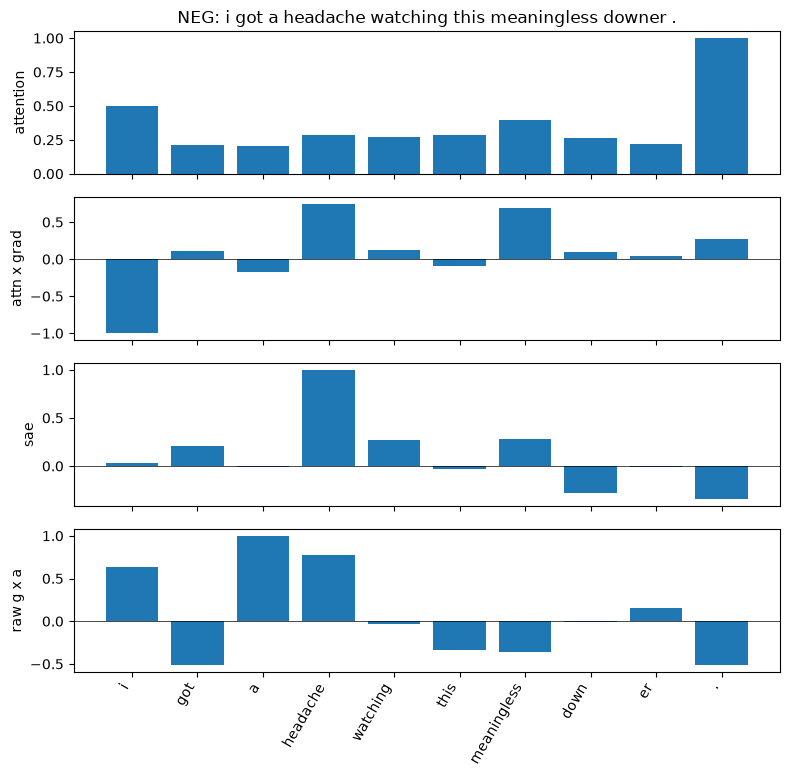

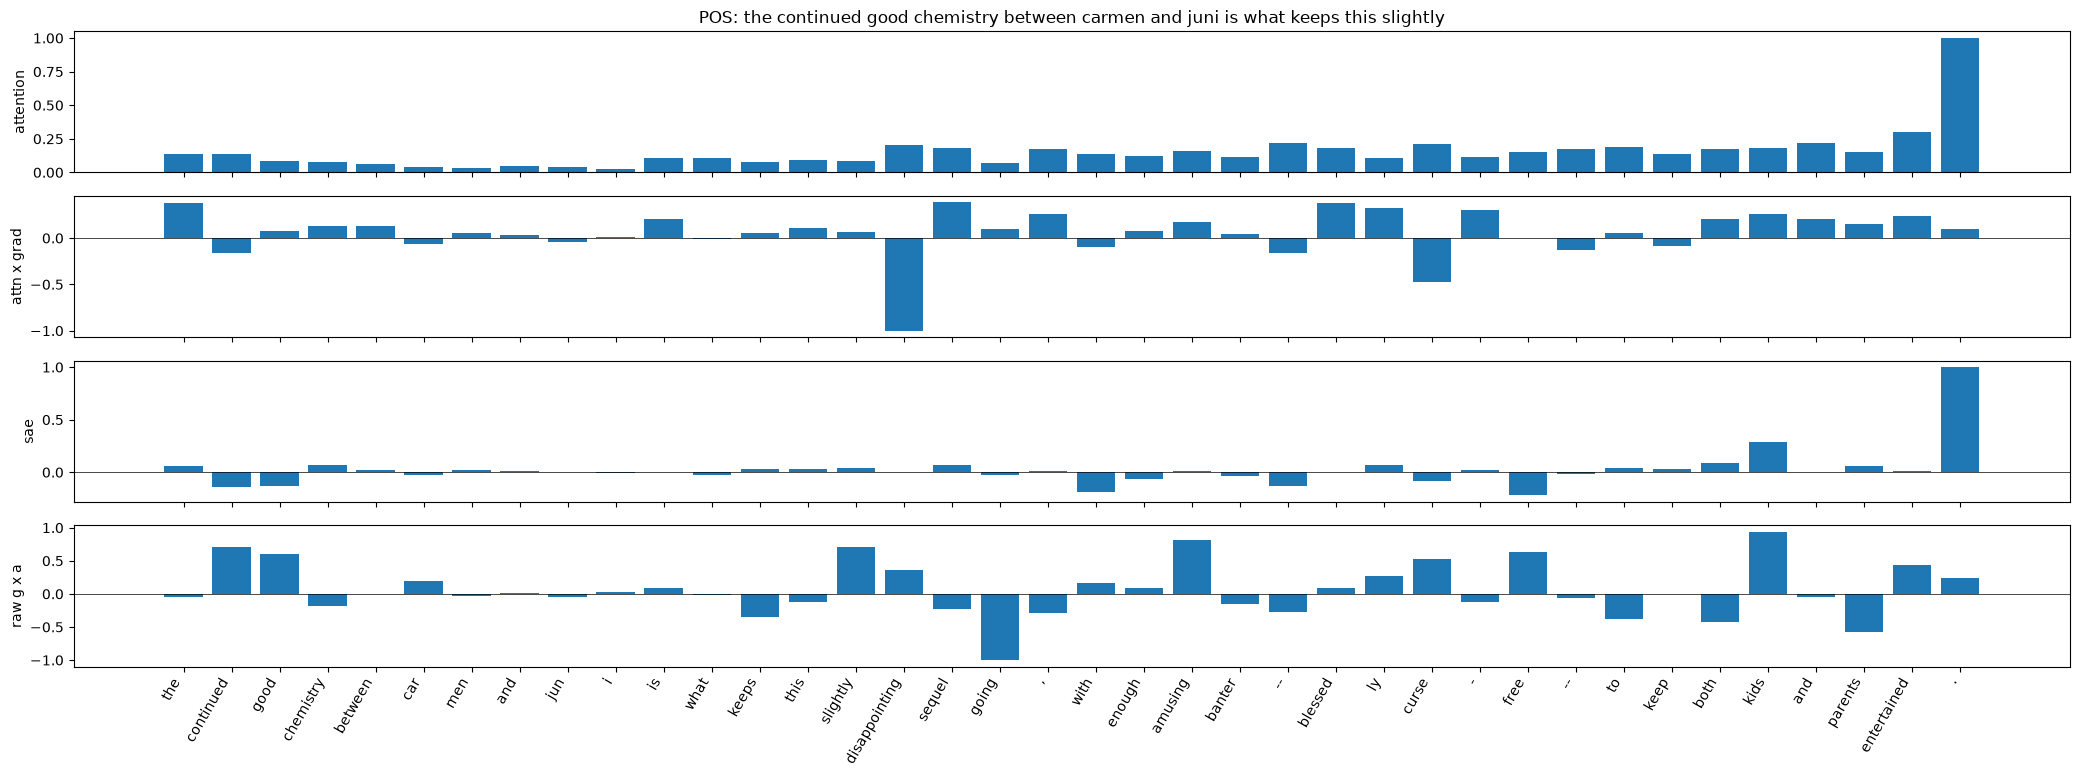

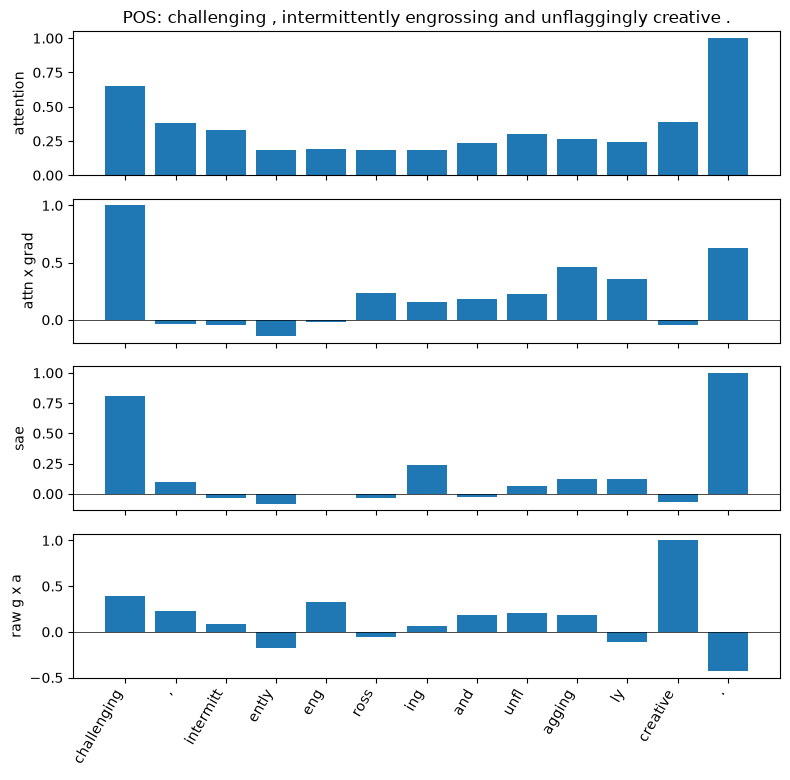

In [36]:
for idx in range(min(3, len(sel))):
    plot_example(idx)

## 7. SAE feature analysis (DEV / TEST design)
For each class we rank SAE features by their mean gradient × activation contribution towards the gold label on the **DEV half**, and list the top features with Neuronpedia links (the `my_label` column of `top_features.csv` is meant to be filled in by hand after inspecting them).

**Stability check:** the top-50 features from the two DEV sub-halves overlap in 26/50 (NEG) and 39/50 (POS) cases. This is far above chance (~0 of 24,576), but shows the NEG ranking is only moderately stable. Several top features fire on essentially every sentence (e.g. 49/49 for NEG), so they are probably generic rather than sentiment-specific; this should be checked on Neuronpedia.

#### Rank features on the DEV half

In [37]:
nd = torch.tensor(feat_n, device=device).clamp(min=1)[:, None]
mean_contrib = feat_sum / nd                                   # [2, d_sae] mean contribution toward gold label
rank_top = {c: torch.argsort(mean_contrib[c], descending=True) for c in (0, 1)}
rank_bot = {c: torch.argsort(mean_contrib[c], descending=False) for c in (0, 1)}
rank_act = {c: torch.argsort(feat_asum[c], descending=True) for c in (0, 1)}
pool = {c: torch.nonzero(feat_ex[c] > 0).squeeze(1) for c in (0, 1)}      # features firing on class-c DEV sentences
assert all(n_ > 0 for n_ in feat_n), "feat_n is zero for a class: DEV half empty"
print("DEV sentences per class [NEG, POS]:", feat_n, "| pool sizes:", [len(pool[c]) for c in (0, 1)])

DEV sentences per class [NEG, POS]: [49, 51] | pool sizes: [12347, 13728]


#### Top features per class (with Neuronpedia links)

In [38]:
top_rows = []
for c in (0, 1):
    print("\nclass", "POS" if c else "NEG", "- top SAE features (DEV half)")
    for fid in rank_top[c][:10].tolist():
        url = f"https://www.neuronpedia.org/gpt2-small/{LAYER}-res-jb/{fid}"
        print(f"  feature {fid:6d}  mean contrib {mean_contrib[c, fid].item():+.3f}  "
              f"fires in {int(feat_ex[c, fid].item())}/{feat_n[c]} sentences  {url}")
        top_rows.append(dict(cls="POS" if c else "NEG", feature=fid, mean_contrib=mean_contrib[c, fid].item(),
                             fires_in=int(feat_ex[c, fid].item()), n_dev=feat_n[c], url=url, my_label=""))
pd.DataFrame(top_rows).to_csv(f"{RES}/top_features.csv", index=False)   # fill 'my_label' by hand after Neuronpedia


class NEG - top SAE features (DEV half)
  feature  18337  mean contrib +0.018  fires in 49/49 sentences  https://www.neuronpedia.org/gpt2-small/8-res-jb/18337
  feature  18435  mean contrib +0.010  fires in 45/49 sentences  https://www.neuronpedia.org/gpt2-small/8-res-jb/18435
  feature  13119  mean contrib +0.006  fires in 49/49 sentences  https://www.neuronpedia.org/gpt2-small/8-res-jb/13119
  feature  14759  mean contrib +0.005  fires in 49/49 sentences  https://www.neuronpedia.org/gpt2-small/8-res-jb/14759
  feature  16396  mean contrib +0.003  fires in 49/49 sentences  https://www.neuronpedia.org/gpt2-small/8-res-jb/16396
  feature  17630  mean contrib +0.003  fires in 49/49 sentences  https://www.neuronpedia.org/gpt2-small/8-res-jb/17630
  feature   7781  mean contrib +0.003  fires in 49/49 sentences  https://www.neuronpedia.org/gpt2-small/8-res-jb/7781
  feature  14214  mean contrib +0.003  fires in 49/49 sentences  https://www.neuronpedia.org/gpt2-small/8-res-jb/14214
  featur

#### Stability of the ranking across DEV sub-halves

In [39]:
# ranking stability: top-50 overlap between the two DEV sub-halves (chance overlap is ~0 out of 24k)
mc_sub = feat_sub / torch.tensor(feat_nsub, device=device).clamp(min=1)[:, :, None]
for c in (0, 1):
    a_ = set(torch.argsort(mc_sub[0, c], descending=True)[:50].tolist())
    b_ = set(torch.argsort(mc_sub[1, c], descending=True)[:50].tolist())
    print("class", "POS" if c else "NEG", "| top-50 overlap between DEV sub-halves:", len(a_ & b_), "/ 50")

class NEG | top-50 overlap between DEV sub-halves: 26 / 50
class POS | top-50 overlap between DEV sub-halves: 39 / 50


### Causal test: ablating SAE features on held-out sentences
We remove the contribution of K features from the layer-8 residual stream at the sentence positions, using decoder linearity: $x_{new} = x - \sum_i f_i W_{dec,i}$. The SAE error term is left untouched. Compared conditions:

- **top**: the K highest-ranked DEV features
- **bottom**: the K most negatively contributing features
- **top_by_act**: top K by activation mass only (a control that ignores the gradient)
- **rand_matched**: random features with similar activation mass (the main control)
- **rand_pool**: random features that fire on the class

Reported as the drop in gold-label margin on the TEST half (p-values printed as `0.0` mean p < 0.001), with a paired effect size against `rand_matched`. Because random sets have almost zero variance, `dz` values are large; the **absolute drop** (compared with a mean margin of 0.245) is the more honest measure of effect size.

**Reading the result.** For POS sentences, `top_by_act` (0.082 at K=50) is almost as effective as `top` (0.101), so the gradient-based ranking adds little over simply choosing high-activation features. The matched-random control matches activation *mass*, but the top features fire in nearly every sentence, so it does not match firing *frequency*; a control matched on both would be stricter.

#### Ablation helper

In [40]:
@torch.no_grad()
def ablate_margins(tokens, sign, f, lo, hi, feat_sets, bs=32):
    """Gold-label margin after removing each feature set's contribution at layer 8 for positions [lo, hi).
    Uses decoder linearity: x_new = x - sum_i f_i * W_dec[i]. The SAE error term is untouched.
    f = sae.encode(clean residual), shape [1, T, d_sae]. All sets are run in batches."""
    out = []
    for s in range(0, len(feat_sets), bs):
        chunk = feat_sets[s:s + bs]
        deltas = []
        for ids in chunk:
            idt = torch.tensor(ids, device=device, dtype=torch.long)
            d = f[0][:, idt] @ sae.W_dec[idt]                   # [T, d_model]
            d[:lo] = 0; d[hi:] = 0
            deltas.append(d)
        D = torch.stack(deltas)                                 # [B, T, d_model]
        lg = model.run_with_hooks(tokens.expand(len(chunk), -1),
                                  fwd_hooks=[(HOOK_NAME, lambda r_, hook, D=D: r_ - D)])[:, -1]
        out.append((sign * (lg[:, POS] - lg[:, NEG])).float().cpu().numpy())
    return np.concatenate(out)

#### Activation-matched random control

In [41]:
# ---- matched random control: for each top feature pick a random pool feature with similar activation mass ----
pool_sorted = {c: pool[c][torch.argsort(feat_asum[c][pool[c]])] for c in (0, 1)}      # ascending activation mass
pos_in_pool = {c: {int(f_): r for r, f_ in enumerate(pool_sorted[c].tolist())} for c in (0, 1)}

def matched_random(c, top_ids, rng, window=50):
    ps = pool_sorted[c].cpu().numpy()
    banned = set(int(x) for x in top_ids)
    chosen = []
    for f_ in top_ids:
        r = pos_in_pool[c].get(int(f_))
        cand = ps if r is None else ps[max(0, r - window): r + window + 1]
        cand = [int(x) for x in cand if int(x) not in banned]
        if not cand:
            cand = [int(x) for x in ps if int(x) not in banned]
        pick = int(rng.choice(cand))
        chosen.append(pick); banned.add(pick)
    return chosen

#### Feature sets for each K

In [42]:
rng = np.random.default_rng(SEED)

def build_sets(c):
    sets, keys = [], []
    pc = pool[c].cpu().numpy()
    for K in KF:
        top = rank_top[c][:K].tolist()
        sets.append(top);                          keys.append((K, "top", 0))
        sets.append(rank_bot[c][:K].tolist());     keys.append((K, "bottom", 0))
        sets.append(rank_act[c][:K].tolist());     keys.append((K, "top_by_act", 0))
        for r in range(R_FEAT):
            sets.append(rng.choice(pc, size=min(K, len(pc)), replace=False).tolist()); keys.append((K, "rand_pool", r))
            sets.append(matched_random(c, top, rng));                                  keys.append((K, "rand_matched", r))
    return sets, keys

#### Held-out TEST half and scope

In [43]:
# CPU-friendly: only the sentence-span scope (roughly half the time).

SCOPES = {"span": lambda sp, T: (sp[0], sp[1])}
test_df = sel[sel.index % 2 == 1]            # held-out half: NOT used to rank features

#### Run the ablations

In [44]:
abl_rows = []
for c in (0, 1):
    sets, keys = build_sets(c)
    sub = test_df[test_df.label == c]
    drops = {s_: np.zeros((len(sub), len(sets))) for s_ in SCOPES}
    for si, (_, row) in enumerate(tqdm(sub.iterrows(), total=len(sub), desc="ablation " + ("POS" if c else "NEG"))):
        t, sp = build_tokens(row["sentence"]); sgn = int(row["sgn"])
        with torch.no_grad():
            _, cache = model.run_with_cache(t, names_filter=HOOK_NAME)
            f_clean = sae.encode(cache[HOOK_NAME])
        base = sgn * logit_diff(t)
        for s_, fn in SCOPES.items():
            lo, hi = fn(sp, t.shape[1])
            drops[s_][si] = base - ablate_margins(t, sgn, f_clean, lo, hi, sets)
    for s_ in SCOPES:
        D_ = drops[s_]
        for K in KF:
            r_ = dict(cls="POS" if c else "NEG", scope=s_, K=K, n_test=len(sub))
            for name in ("top", "bottom", "top_by_act"):
                r_[name] = D_[:, keys.index((K, name, 0))].mean()
            for name in ("rand_pool", "rand_matched"):
                js = [j for j, k_ in enumerate(keys) if k_[0] == K and k_[1] == name]
                per_draw = D_[:, js].mean(0)                    # mean over sentences, one value per random draw
                r_[name + "_mean"] = per_draw.mean()
                r_[name + "_sd"] = per_draw.std(ddof=1) if len(per_draw) > 1 else np.nan
                if name == "rand_matched":
                    d = D_[:, keys.index((K, "top", 0))] - D_[:, js].mean(1)      # paired over sentences
                    sd = d.std(ddof=1) if len(d) > 1 else np.nan
                    r_["top_vs_matched_dz"] = d.mean() / sd if sd and sd > 0 else np.nan
                    r_["top_vs_matched_p"] = stats.ttest_1samp(d, 0.0).pvalue if len(d) > 2 and sd and sd > 0 else np.nan
            abl_rows.append(r_)

ablation NEG:   0%|          | 0/51 [00:00<?, ?it/s]

ablation POS:   0%|          | 0/49 [00:00<?, ?it/s]

#### Results table

In [45]:
abl = pd.DataFrame(abl_rows)
abl.to_csv(f"{RES}/feature_ablation.csv", index=False)
print(abl.round(3).to_string(index=False))

cls scope  K  n_test   top  bottom  top_by_act  rand_pool_mean  rand_pool_sd  rand_matched_mean  rand_matched_sd  top_vs_matched_dz  top_vs_matched_p
NEG  span  1      51 0.010  -0.010      -0.001           0.000         0.000              0.000            0.003              0.778               0.0
NEG  span  5      51 0.023  -0.014       0.006           0.000         0.000             -0.005            0.004              1.459               0.0
NEG  span 10      51 0.029  -0.021      -0.004          -0.000         0.000             -0.010            0.008              1.502               0.0
NEG  span 20      51 0.039  -0.021       0.000           0.000         0.000             -0.011            0.004              1.781               0.0
NEG  span 50      51 0.048  -0.028       0.011           0.000         0.001             -0.014            0.003              1.909               0.0
POS  span  1      49 0.034  -0.003       0.005           0.000         0.000              0.002     

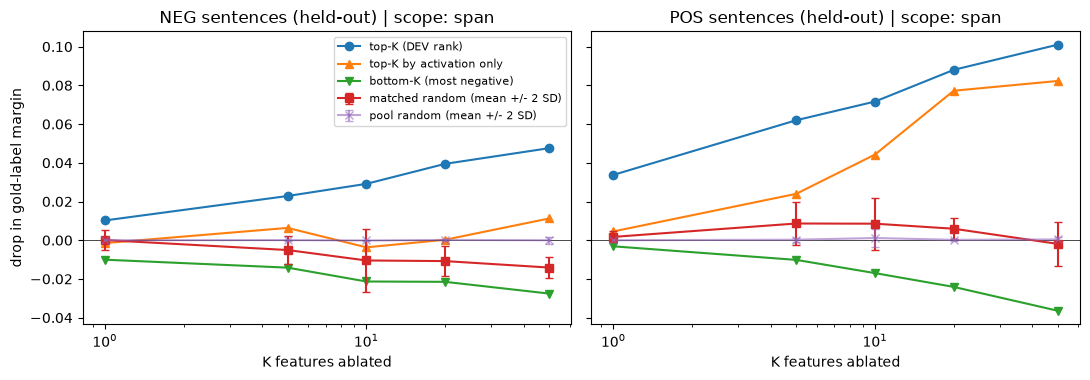

In [46]:
for scope in SCOPES:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
    for a_, c in zip(ax, ["NEG", "POS"]):
        g = abl[(abl.cls == c) & (abl.scope == scope)]
        a_.plot(g.K, g.top, marker="o", label="top-K (DEV rank)")
        a_.plot(g.K, g.top_by_act, marker="^", label="top-K by activation only")
        a_.plot(g.K, g.bottom, marker="v", label="bottom-K (most negative)")
        a_.errorbar(g.K, g.rand_matched_mean, yerr=2 * g.rand_matched_sd.fillna(0), marker="s", capsize=3,
                    label="matched random (mean +/- 2 SD)")
        a_.errorbar(g.K, g.rand_pool_mean, yerr=2 * g.rand_pool_sd.fillna(0), marker="x", capsize=3, alpha=0.6,
                    label="pool random (mean +/- 2 SD)")
        a_.axhline(0, color="k", lw=0.5)
        a_.set(title=f"{c} sentences (held-out) | scope: {scope}", xlabel="K features ablated", xscale="log")
    ax[0].set_ylabel("drop in gold-label margin"); ax[0].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{FIG}/feature_ablation_{scope}.png", dpi=150); plt.show()

## 8. Non-SAE baseline: difference-in-means direction
Is a sparse dictionary needed at all? We compute a single sentiment direction (mean residual of positive DEV sentences minus negative ones), project it out of the sentence positions on the TEST half, and compare with 15 null directions obtained by shuffling the labels.

On POS sentences one direction drops the margin by **0.123** (null: −0.006 ± 0.025), more than the top-50 SAE features (0.101). On NEG sentences the effect is slightly *negative* (−0.017), i.e. removing the direction makes negative sentences marginally more confidently negative. This class asymmetry is not explained here. One possible cause is that the projection is not mean-centred: it also removes the class-independent component along the direction.This is consistent with the centred check below, where the NEG effect becomes positive (+0.037) and the POS effect falls to 0.055, below the top-50 SAE features (0.101).

#### Difference-in-means direction and null directions

In [47]:
# ---- NON-SAE baseline: difference-in-means sentiment direction vs label-shuffled null directions ----
D_vecs = torch.stack([v for _, v in dev_vecs])                        # [n_dev, d_model] mean span residual per DEV sentence
D_lab = torch.tensor([l for l, _ in dev_vecs])

def diffmean(labels):
    d = D_vecs[labels == 1].mean(0) - D_vecs[labels == 0].mean(0)
    return (d / d.norm()).to(device)

u_sent = diffmean(D_lab)
g_ = torch.Generator().manual_seed(SEED)
null_dirs = [diffmean(D_lab[torch.randperm(len(D_lab), generator=g_)]) for _ in range(R_DIR)]

#### Projection helper

In [48]:
@torch.no_grad()
def project_out_margins(tokens, sign, resid, lo, hi, dirs):
    """Margin after removing the component along each direction from the residual (positions [lo, hi))."""
    U = torch.stack(dirs)                                             # [B, d_model]
    coef = torch.einsum("td,bd->bt", resid[0], U)                     # [B, T]
    delta = coef[:, :, None] * U[:, None, :]                          # [B, T, d_model]
    delta[:, :lo] = 0; delta[:, hi:] = 0
    lg = model.run_with_hooks(tokens.expand(len(dirs), -1), fwd_hooks=[(HOOK_NAME, lambda r_, hook: r_ - delta)])[:, -1]
    return (sign * (lg[:, POS] - lg[:, NEG])).float().cpu().numpy()

#### Run the direction ablation

In [49]:
dir_rows = []
for s_, fn in SCOPES.items():
    per_class = {0: [], 1: []}
    for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="direction ablation " + s_):
        t, sp = build_tokens(row["sentence"]); sgn = int(row["sgn"])
        with torch.no_grad():
            _, cache = model.run_with_cache(t, names_filter=HOOK_NAME)
        base = sgn * logit_diff(t)
        lo, hi = fn(sp, t.shape[1])
        m = project_out_margins(t, sgn, cache[HOOK_NAME], lo, hi, [u_sent] + null_dirs)
        per_class[int(row["label"])].append(base - m)                 # [1 + R_DIR]
    for c in (0, 1):
        arr = np.stack(per_class[c])                                  # [n_sent, 1 + R_DIR]
        null_means = arr[:, 1:].mean(0)
        d = arr[:, 0] - arr[:, 1:].mean(1)
        sd = d.std(ddof=1) if len(d) > 1 else np.nan
        dir_rows.append(dict(cls="POS" if c else "NEG", scope=s_, n_test=len(arr),
                             drop_diffmean_dir=arr[:, 0].mean(), null_mean=null_means.mean(),
                             null_sd=null_means.std(ddof=1) if len(null_means) > 1 else np.nan,
                             dz_vs_null=d.mean() / sd if sd and sd > 0 else np.nan,
                             p_vs_null=stats.ttest_1samp(d, 0.0).pvalue if len(d) > 2 and sd and sd > 0 else np.nan))

direction ablation span:   0%|          | 0/100 [00:00<?, ?it/s]

#### Results table

In [50]:
dir_df = pd.DataFrame(dir_rows)
dir_df.to_csv(f"{RES}/direction_baseline.csv", index=False)
print(dir_df.round(3).to_string(index=False))
print("\nCompare 'drop_diffmean_dir' (ONE direction) with the K-feature rows of feature_ablation.csv.")

cls scope  n_test  drop_diffmean_dir  null_mean  null_sd  dz_vs_null  p_vs_null
NEG  span      51             -0.017     -0.002    0.015      -0.380      0.009
POS  span      49              0.123     -0.006    0.025       2.164      0.000

Compare 'drop_diffmean_dir' (ONE direction) with the K-feature rows of feature_ablation.csv.


### Robustness check: centred projection
Same test as above, but only the part of the projection that varies around its DEV mean is removed. TResult: drop 0.037 (NEG) and 0.055 (POS), null means about 0.001 and −0.001.

#### Centred projection helper and directions

In [51]:
# ---- Robustness check: mean-CENTRED projection for the difference-in-means direction ----
# Removes only the part of the projection that varies around its DEV mean, not the shared offset.
@torch.no_grad()
def project_out_centered(tokens, sign, resid, lo, hi, dirs, offsets):
    U = torch.stack(dirs)                                             # [B, d_model]
    coef = torch.einsum("td,bd->bt", resid[0], U) - offsets[:, None]  # centred coefficients [B, T]
    delta = coef[:, :, None] * U[:, None, :]
    delta[:, :lo] = 0; delta[:, hi:] = 0
    lg = model.run_with_hooks(tokens.expand(len(dirs), -1), fwd_hooks=[(HOOK_NAME, lambda r_, hook: r_ - delta)])[:, -1]
    return (sign * (lg[:, POS] - lg[:, NEG])).float().cpu().numpy()

all_dirs = [u_sent] + null_dirs
offsets = torch.stack([(D_vecs.to(device) @ u).mean() for u in all_dirs])   # DEV mean projection per direction

#### Run the centred direction ablation

In [52]:
cent_rows = []
for s_, fn in SCOPES.items():
    per_class = {0: [], 1: []}
    for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="centred direction ablation " + s_):
        t, sp = build_tokens(row["sentence"]); sgn = int(row["sgn"])
        with torch.no_grad():
            _, cache = model.run_with_cache(t, names_filter=HOOK_NAME)
        base = sgn * logit_diff(t)
        lo, hi = fn(sp, t.shape[1])
        m = project_out_centered(t, sgn, cache[HOOK_NAME], lo, hi, all_dirs, offsets)
        per_class[int(row["label"])].append(base - m)
    for c in (0, 1):
        arr = np.stack(per_class[c])
        cent_rows.append(dict(cls="POS" if c else "NEG", scope=s_, n_test=len(arr),
                              drop_diffmean_dir_centred=arr[:, 0].mean(), null_mean=arr[:, 1:].mean()))

centred direction ablation span:   0%|          | 0/100 [00:00<?, ?it/s]

#### Results table

In [53]:
cent_df = pd.DataFrame(cent_rows)
cent_df.to_csv(f"{RES}/direction_baseline_centred.csv", index=False)
print(cent_df.round(3).to_string(index=False))

cls scope  n_test  drop_diffmean_dir_centred  null_mean
NEG  span      51                      0.037      0.001
POS  span      49                      0.055     -0.001


## 9. SAE reconstruction fidelity at this layer
We replace the layer-8 residual by its SAE reconstruction (error term **dropped**) and re-measure the margin. The mean margin is almost unchanged (0.220 vs. 0.228), but only **68%** of the sentences are still classified correctly, although all of them were correct originally. So the SAE preserves the average signal but loses the decision on about a third of the examples. This is a reason to treat SAE-based explanations here with caution, but note that this splice also replaces the **BOS** position (which has a very large norm and is excluded from the reconstruction check in Section 2) and the whole few-shot prefix. The next cell repeats the test with BOS untouched: the result is unchanged (68% still correct, mean margin 0.221), so BOS is not the cause. The few-shot prefix is still replaced in both versions.

In [54]:
# ---- SAE reconstruction fidelity at this layer (error term DROPPED) ----
@torch.no_grad()
def margin_spliced(tokens, sign):
    lg = model.run_with_hooks(tokens, fwd_hooks=[(HOOK_NAME, lambda act, hook: sae.decode(sae.encode(act)))])[0, -1]
    return sign * (lg[POS] - lg[NEG]).item()

sub = sel.sample(min(100, len(sel)), random_state=SEED)
o_, s_sp = [], []
for _, r in sub.iterrows():
    t, _ = build_tokens(r["sentence"])
    o_.append(float(r["margin"])); s_sp.append(margin_spliced(t, int(r["sgn"])))
o_, s_sp = np.array(o_), np.array(s_sp)
SPLICE_MEAN_ORIG, SPLICE_MEAN_SAE, SPLICE_STILL_OK = float(o_.mean()), float(s_sp.mean()), float((s_sp > 0).mean())
print("mean margin original:", round(SPLICE_MEAN_ORIG, 3), "| spliced-in SAE:", round(SPLICE_MEAN_SAE, 3))
print("still correct after splicing:", round(SPLICE_STILL_OK, 3))


mean margin original: 0.228 | spliced-in SAE: 0.22
still correct after splicing: 0.68


### Robustness check: SAE splice excluding BOS

In [55]:
# ---- Robustness check: splice the SAE in at NON-BOS positions only ----
@torch.no_grad()
def margin_spliced_nobos(tokens, sign):
    def hook(act, hook):
        out = act.clone()
        out[:, 1:] = sae.decode(sae.encode(act[:, 1:]))      # keep BOS untouched
        return out
    lg = model.run_with_hooks(tokens, fwd_hooks=[(HOOK_NAME, hook)])[0, -1]
    return sign * (lg[POS] - lg[NEG]).item()

s_nobos = np.array([margin_spliced_nobos(build_tokens(r["sentence"])[0], int(r["sgn"])) for _, r in sub.iterrows()])
print("mean margin original:", round(float(o_.mean()), 3), "| spliced (non-BOS only):", round(float(s_nobos.mean()), 3))
print("still correct, SAE at all positions :", round(SPLICE_STILL_OK, 3))
print("still correct, SAE at non-BOS only   :", round(float((s_nobos > 0).mean()), 3))

mean margin original: 0.228 | spliced (non-BOS only): 0.221
still correct, SAE at all positions : 0.68
still correct, SAE at non-BOS only   : 0.68


## 10. Reproducibility
Library versions and run configuration are written to `results/run_info.json`; a summary table for the README is generated, and `requirements.txt` and `.gitignore` are created.

In [56]:
import importlib.metadata as md_
VERS = {}
for p in ["torch", "transformer-lens", "sae-lens", "datasets", "pandas", "scipy", "numpy", "matplotlib"]:
    try:
        VERS[p] = md_.version(p)
    except Exception:
        VERS[p] = "unknown"

run_info = dict(QUICK=QUICK, seed=SEED, layer=LAYER, sae_release=SAE_RELEASE, hook=HOOK_NAME,
                n_per_class=N_PER_CLASS, n_evaluated=len(sel), class_counts={int(k): int(v) for k, v in sel.label.value_counts().items()},
                few_shot_accuracy_sst2_val=ACC, ks=KS, r_random=R_RANDOM, kf=KF, r_feat=R_FEAT, r_dir=R_DIR,
                eps_denom=EPS_DENOM, prompt_prefix=PREFIX, prompt_suffix=SUFFIX, versions=VERS,
                splice_mean_margin_orig=SPLICE_MEAN_ORIG, splice_mean_margin_sae=SPLICE_MEAN_SAE,
                splice_fraction_still_correct=SPLICE_STILL_OK)
with open(f"{RES}/run_info.json", "w") as fh:
    json.dump(run_info, fh, indent=2)
print(json.dumps({k: v for k, v in run_info.items() if k not in ("prompt_prefix",)}, indent=2))

{
  "QUICK": false,
  "seed": 0,
  "layer": 8,
  "sae_release": "gpt2-small-res-jb",
  "hook": "blocks.8.hook_resid_pre",
  "n_per_class": 100,
  "n_evaluated": 200,
  "class_counts": {
    "0": 100,
    "1": 100
  },
  "few_shot_accuracy_sst2_val": 0.658256880733945,
  "ks": [
    1,
    2,
    3,
    5,
    8
  ],
  "r_random": 3,
  "kf": [
    1,
    5,
    10,
    20,
    50
  ],
  "r_feat": 5,
  "r_dir": 15,
  "eps_denom": 0.25,
  "prompt_suffix": "\nSentiment:",
  "versions": {
    "torch": "2.14.0",
    "transformer-lens": "3.9.0",
    "sae-lens": "6.54.4",
    "datasets": "5.0.1",
    "pandas": "3.0.6",
    "scipy": "1.17.1",
    "numpy": "2.4.6",
    "matplotlib": "3.11.2"
  },
  "splice_mean_margin_orig": 0.22796751976013183,
  "splice_mean_margin_sae": 0.22035242080688477,
  "splice_fraction_still_correct": 0.68
}


In [57]:
def cell(g, k, m):
    r = g[(g.k == k) & (g.metric == m)]
    if r.empty or np.isnan(r["mean"].iloc[0]):
        return "n/a"
    r = r.iloc[0]
    return f"{r['mean']:.3f} [{r.lo:.3f}, {r.hi:.3f}]"

lines = []
for metric, title in [("comp", "Comprehensiveness (higher = more faithful), mean [95% bootstrap CI]"),
                      ("suff", "Sufficiency (lower = more faithful), mean [95% bootstrap CI]")]:
    lines += [f"**{title}**", "", "| method | k=1 | k=3 | k=5 |", "|---|---|---|---|"]
    for method in METHODS_ALL:
        g = summ[summ.method == method]
        lines.append(f"| {method} | " + " | ".join(cell(g, k, metric) for k in (1, 3, 5)) + " |")
    lines.append("")

lines += ["**Rank agreement (mean over sentences)**", "", "```", agree_df.drop(columns="id").mean().round(3).to_string(), "```", ""]
lines += ["**Few-shot accuracy (SST-2 val):** %.3f | **N evaluated:** %d | class counts: %s" % (ACC, len(sel), run_info["class_counts"]), ""]
lines += ["**SAE spliced-in:** mean margin %.3f (original %.3f), fraction still correct %.3f" %
          (SPLICE_MEAN_SAE, SPLICE_MEAN_ORIG, SPLICE_STILL_OK), ""]
lines += ["**Held-out feature ablation (scope=span)**", "", "```",
          abl[abl.scope == "span"][["cls", "K", "top", "top_by_act", "bottom", "rand_matched_mean", "rand_matched_sd",
                                    "rand_pool_mean", "top_vs_matched_dz", "top_vs_matched_p"]].round(3).to_string(index=False), "```", ""]
lines += ["**Direction baseline (non-SAE)**", "", "```", dir_df.round(3).to_string(index=False), "```"]

with open(f"{RES}/summary_for_readme.md", "w") as fh:
    fh.write("\n".join(lines))
print("\n".join(lines))

**Comprehensiveness (higher = more faithful), mean [95% bootstrap CI]**

| method | k=1 | k=3 | k=5 |
|---|---|---|---|
| attention | 0.028 [0.013, 0.043] | 0.053 [0.014, 0.091] | 0.095 [0.049, 0.139] |
| attn_x_grad | 0.087 [0.062, 0.113] | 0.194 [0.154, 0.231] | 0.234 [0.189, 0.276] |
| sae | -0.038 [-0.056, -0.020] | 0.039 [0.005, 0.074] | 0.080 [0.040, 0.120] |
| raw_gradxact | 0.028 [0.007, 0.050] | 0.073 [0.040, 0.107] | 0.107 [0.071, 0.142] |
| last_k | 0.032 [0.017, 0.047] | 0.040 [0.024, 0.055] | 0.073 [0.054, 0.090] |
| random | 0.003 [-0.012, 0.017] | 0.010 [-0.016, 0.036] | 0.039 [0.008, 0.069] |

**Sufficiency (lower = more faithful), mean [95% bootstrap CI]**

| method | k=1 | k=3 | k=5 |
|---|---|---|---|
| attention | 0.230 [0.210, 0.249] | 0.182 [0.152, 0.212] | 0.145 [0.109, 0.181] |
| attn_x_grad | 0.170 [0.146, 0.195] | 0.075 [0.046, 0.102] | -0.001 [-0.033, 0.029] |
| sae | 0.204 [0.180, 0.228] | 0.142 [0.115, 0.169] | 0.087 [0.055, 0.118] |
| raw_gradxact | 0.183 

In [58]:
req_names = {"torch": "torch", "transformer-lens": "transformer_lens", "sae-lens": "sae-lens", "datasets": "datasets",
             "pandas": "pandas", "scipy": "scipy", "numpy": "numpy", "matplotlib": "matplotlib"}
req = [f"{pkg}=={VERS[pkg]}" if VERS.get(pkg, "unknown") != "unknown" else req_names[pkg] for pkg in req_names]
req += ["tqdm", "jupyter", "ipywidgets"]
with open("requirements.txt", "w") as fh:
    fh.write("\n".join(req) + "\n")

gitignore = """# Python
__pycache__/
*.pyc
.venv/
venv/
.ipynb_checkpoints/
# OS / editor
.DS_Store
.vscode/
.idea/
# caches / large files / checkpoints
.cache/
*.safetensors
results/_ckpt.pkl
results/quick/
figures/quick/
"""
with open(".gitignore", "w") as fh:
    fh.write(gitignore)
print(open("requirements.txt").read())

torch==2.14.0
transformer-lens==3.9.0
sae-lens==6.54.4
datasets==5.0.1
pandas==3.0.6
scipy==1.17.1
numpy==2.4.6
matplotlib==3.11.2
tqdm
jupyter
ipywidgets



## Discussion
**What the results support.** (1) Gradient-based attention scores (attention × gradient) pick out tokens that are most important for the model's output, better than attention alone (bootstrap CIs do not overlap with attention's at k = 1, 3, 5; no direct paired test was run). (2) SAE features chosen on a DEV split transfer to held-out sentences: ablating them hurts the gold-label margin more than matched random features, so the SAE does isolate directions that matter for this task. (3) Token-level SAE attribution is not more faithful than raw gradient × activation (comprehensiveness 0.080 vs 0.107 at k=5, not significant after correction, and significantly worse at k=1). By the identity in Section 4 it equals the raw score minus the bias and error terms, and the two rankings differ substantially (mean Spearman −0.155).